In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import joblib
import json
import warnings
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow.keras.models import load_model

warnings.filterwarnings('ignore')
sns.set()
sns.set_context('talk')

In [2]:
# ── Data ────────────────────────────────────────────────────────────────────
with open('../../config.json') as f:
    cfg = json.load(f)

target    = cfg['rc']
file_name = cfg['rc_file_name']

data = pd.read_csv(f'../../data/{file_name}.csv')
X = data.drop(columns=[target])
y = data[target]

# Seeds utilisées lors de l'entraînement (même générateur que dans les notebooks)
master_rng = np.random.default_rng(seed=99)
seeds = master_rng.choice(10000, size=4, replace=False).tolist()
print("Seeds :", seeds)

Seeds : [5650, 7575, 5059, 9578]


In [3]:
# ── Évaluation par seed puis moyenne ────────────────────────────────────────
from tensorflow.keras.models import load_model

model_types = ['Random Forest', 'XGBoost', 'ANN']
# seed -> model_type -> metrics
per_seed_results = {mt: [] for mt in model_types}

for seed in seeds:
    X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
        X, y, test_size=0.2, random_state=seed
    )

    # ANN a besoin du scaler de sa seed
    scaler_s = joblib.load(f'saved_models/scaler_seed_{seed}.pkl')
    X_test_scaled_s = pd.DataFrame(scaler_s.transform(X_test_s), columns=X_test_s.columns)

    models_s = {
        'Random Forest': joblib.load(f'saved_models/random_forest_seed_{seed}.pkl'),
        'XGBoost':       joblib.load(f'saved_models/xgboost_seed_{seed}.pkl'),
        'ANN':           load_model(f'saved_models/ann_seed_{seed}.keras'),
    }

    for name, model in models_s.items():
        if name == 'ANN':
            y_pred = model.predict(X_test_scaled_s, verbose=0).flatten()
        else:
            y_pred = model.predict(X_test_s)

        per_seed_results[name].append({
            'R²':   r2_score(y_test_s, y_pred),
            'MAE':  mean_absolute_error(y_test_s, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_test_s, y_pred)),
        })

# ── Moyenne et écart-type sur les 4 seeds ───────────────────────────────────
rows = []
for name in model_types:
    r2s   = [d['R²']   for d in per_seed_results[name]]
    maes  = [d['MAE']  for d in per_seed_results[name]]
    rmses = [d['RMSE'] for d in per_seed_results[name]]
    rows.append({
        'Model':       name,
        'R² mean':     round(np.mean(r2s),   4),
        'R² std':      round(np.std(r2s),    4),
        'MAE mean':    round(np.mean(maes),  4),
        'MAE std':     round(np.std(maes),   4),
        'RMSE mean':   round(np.mean(rmses), 4),
        'RMSE std':    round(np.std(rmses),  4),
    })

metrics_df = pd.DataFrame(rows).set_index('Model')

# Alias courts pour les graphiques
preds_mean = {
    name: np.mean([d['R²'] for d in per_seed_results[name]])
    for name in model_types
}

print(metrics_df.to_string())

               R² mean  R² std  MAE mean  MAE std  RMSE mean  RMSE std
Model                                                                 
Random Forest   0.8699  0.0570    1.9978   0.1414     2.8801    0.4896
XGBoost         0.8848  0.0442    1.8847   0.1627     2.7246    0.4008
ANN             0.7879  0.0668    2.7263   0.3227     3.7188    0.4860


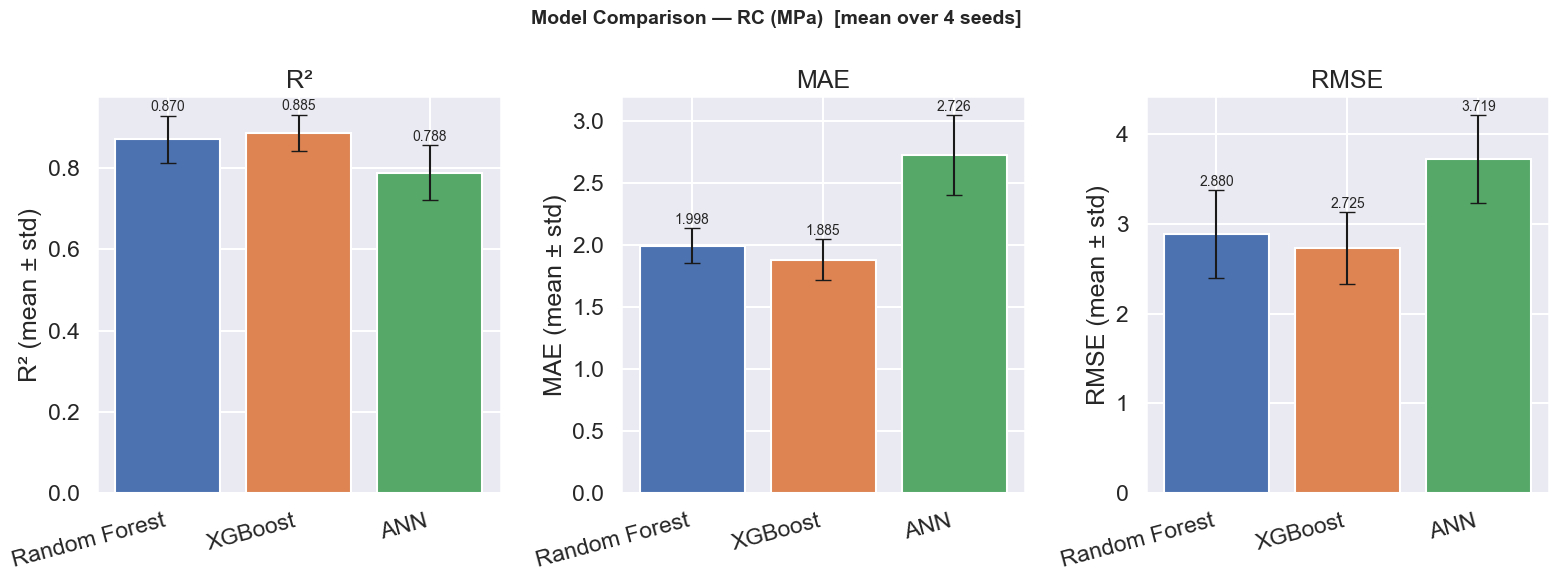

In [4]:
# ── 1. Metrics bar chart (mean ± std) ────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
colors = ['#4C72B0', '#DD8452', '#55A868']

for ax, metric in zip(axes, ['R²', 'MAE', 'RMSE']):
    means = metrics_df[f'{metric} mean']
    stds  = metrics_df[f'{metric} std']
    bars  = ax.bar(metrics_df.index, means, yerr=stds, color=colors,
                   capsize=6, error_kw={'elinewidth': 1.5})
    ax.set_title(metric)
    ax.set_ylabel(f'{metric} (mean ± std)')
    ax.set_xticklabels(metrics_df.index, rotation=15, ha='right')
    for bar, val, std in zip(bars, means, stds):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + std + 0.005 * bar.get_height(),
                f'{val:.3f}', ha='center', va='bottom', fontsize=10)

plt.suptitle('Model Comparison — RC (MPa)  [mean over 4 seeds]', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('saved_models/comparison_metrics.png', dpi=150, bbox_inches='tight')
plt.show()

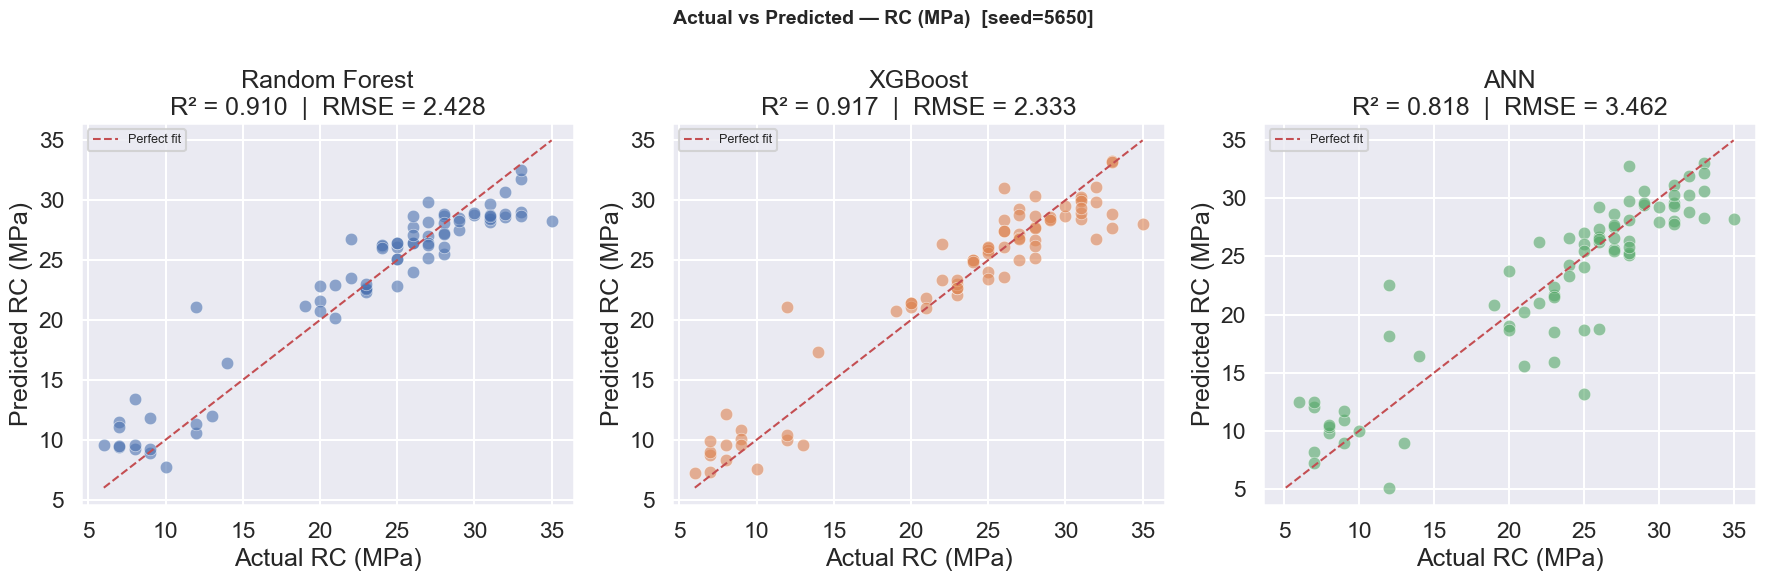

In [5]:
# ── 2. Actual vs Predicted — une seed représentative (première seed) ─────────
seed_ref = seeds[0]
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X, y, test_size=0.2, random_state=seed_ref)
scaler_r    = joblib.load(f'saved_models/scaler_seed_{seed_ref}.pkl')
X_test_sc_r = pd.DataFrame(scaler_r.transform(X_test_r), columns=X_test_r.columns)

preds_ref = {
    'Random Forest': joblib.load(f'saved_models/random_forest_seed_{seed_ref}.pkl').predict(X_test_r),
    'XGBoost':       joblib.load(f'saved_models/xgboost_seed_{seed_ref}.pkl').predict(X_test_r),
    'ANN':           load_model(f'saved_models/ann_seed_{seed_ref}.keras').predict(X_test_sc_r, verbose=0).flatten(),
}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (name, y_pred), color in zip(axes, preds_ref.items(), colors):
    ax.scatter(y_test_r, y_pred, alpha=0.6, color=color, edgecolors='white', linewidths=0.5)
    lims = [min(y_test_r.min(), y_pred.min()), max(y_test_r.max(), y_pred.max())]
    ax.plot(lims, lims, 'r--', linewidth=1.5, label='Perfect fit')
    ax.set_xlabel('Actual RC (MPa)')
    ax.set_ylabel('Predicted RC (MPa)')
    r2   = r2_score(y_test_r, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test_r, y_pred))
    ax.set_title(f'{name}\nR² = {r2:.3f}  |  RMSE = {rmse:.3f}')
    ax.legend(fontsize=9)

plt.suptitle(f'Actual vs Predicted — RC (MPa)  [seed={seed_ref}]', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('saved_models/comparison_actual_vs_pred.png', dpi=150, bbox_inches='tight')
plt.show()

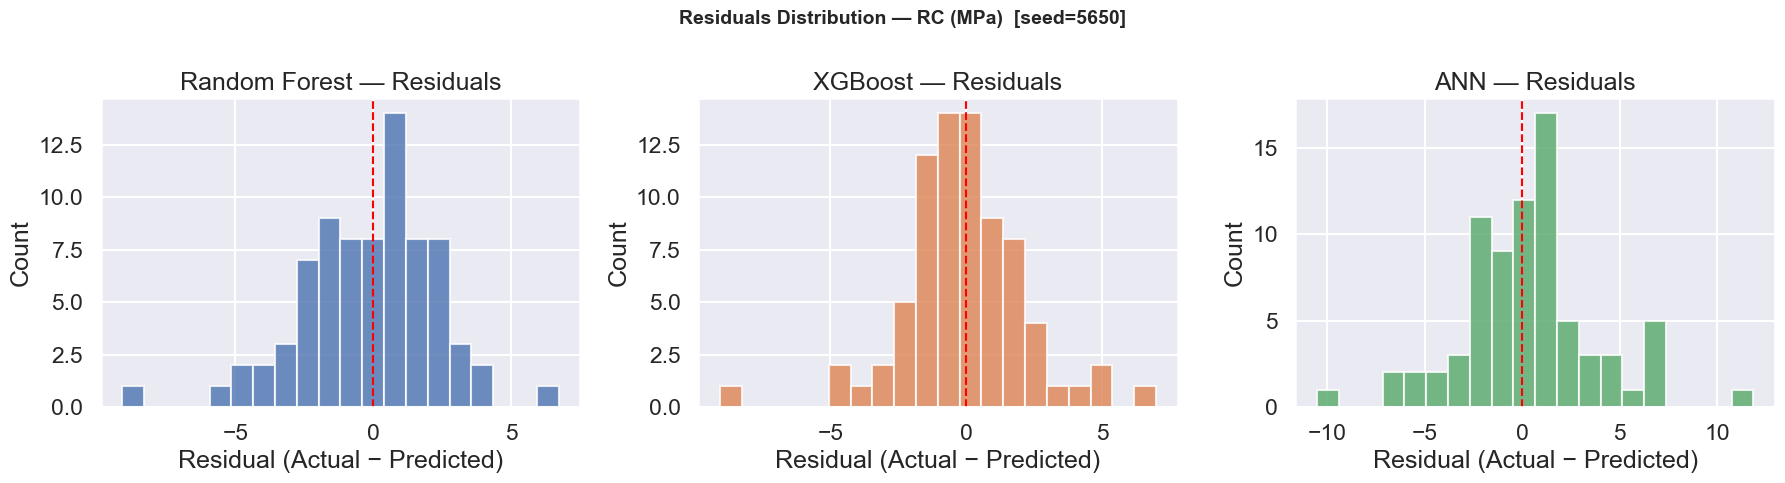

In [6]:
# ── 3. Residuals distribution (seed représentative) ──────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, y_pred), color in zip(axes, preds_ref.items(), colors):
    residuals = np.array(y_test_r) - y_pred
    ax.hist(residuals, bins=20, color=color, edgecolor='white', alpha=0.8)
    ax.axvline(0, color='red', linestyle='--', linewidth=1.5)
    ax.set_xlabel('Residual (Actual − Predicted)')
    ax.set_ylabel('Count')
    ax.set_title(f'{name} — Residuals')

plt.suptitle(f'Residuals Distribution — RC (MPa)  [seed={seed_ref}]', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('saved_models/comparison_residuals.png', dpi=150, bbox_inches='tight')
plt.show()

In [7]:
# ── 4. Résumé final ───────────────────────────────────────────────────────────
print('===== Final Metrics Summary (mean ± std over 4 seeds) =====')
print(metrics_df.to_string())

print(f'\nBest R²:   {metrics_df["R² mean"].idxmax()} ({metrics_df["R² mean"].max():.4f} ± {metrics_df.loc[metrics_df["R² mean"].idxmax(), "R² std"]:.4f})')
print(f'Best MAE:  {metrics_df["MAE mean"].idxmin()} ({metrics_df["MAE mean"].min():.4f} ± {metrics_df.loc[metrics_df["MAE mean"].idxmin(), "MAE std"]:.4f})')
print(f'Best RMSE: {metrics_df["RMSE mean"].idxmin()} ({metrics_df["RMSE mean"].min():.4f} ± {metrics_df.loc[metrics_df["RMSE mean"].idxmin(), "RMSE std"]:.4f})')

===== Final Metrics Summary (mean ± std over 4 seeds) =====
               R² mean  R² std  MAE mean  MAE std  RMSE mean  RMSE std
Model                                                                 
Random Forest   0.8699  0.0570    1.9978   0.1414     2.8801    0.4896
XGBoost         0.8848  0.0442    1.8847   0.1627     2.7246    0.4008
ANN             0.7879  0.0668    2.7263   0.3227     3.7188    0.4860

Best R²:   XGBoost (0.8848 ± 0.0442)
Best MAE:  XGBoost (1.8847 ± 0.1627)
Best RMSE: XGBoost (2.7246 ± 0.4008)
